In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import yfinance as yf
from mpl_toolkits.mplot3d import Axes3D
from numpy.linalg import inv
from sklearn.neighbors import NearestNeighbors
from scipy.spatial import distance

In [69]:
import yfinance as yf
tickers = ['MSFT', 'F', 'BAC']
df = yf.download(tickers, start = '2007-01-01', end = '2007-08-01', auto_adjust = False)['Adj Close']

jan_prices = df.loc['2007-01-01':'2007-01-31']
jul_prices = df.loc['2007-07-01':'2007-07-31']

jan_returns = jan_prices.dropna()
jul_returns = jul_prices.dropna()

delta = pd.concat([jan_returns, jul_returns])

delta = delta.rename(columns = {
    'MSFT': 'msft_adj',
    'F':'f_adj',
    'BAC':'bac_adj'
})


delta = delta * 100


[*********************100%***********************]  3 of 3 completed


In [71]:
delta.describe()

Ticker,bac_adj,f_adj,msft_adj
count,41.000000,41.000000,41.000000
mean,3435.155729,417.426370,2139.631676
std,125.074934,25.797107,44.027564
min,3223.506165,373.329139,2051.426697
25%,3336.996078,399.675822,2104.500198
50%,3404.677963,412.600851,2140.363121
75%,3565.706253,434.473562,2179.023552
max,3589.112473,479.213572,2229.750443


In [72]:
delta.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 41 entries, 2007-01-03 to 2007-07-31
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   bac_adj   41 non-null     float64
 1   f_adj     41 non-null     float64
 2   msft_adj  41 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


In [39]:
delta.shape

(39, 3)

In [40]:
delta_missing = delta.isna().value_counts()
delta_missing

bac_adj  f_adj  msft_adj
False    False  False       39
Name: count, dtype: int64

In [73]:
N, d = delta_clean.shape
delta_clean = pd.DataFrame(100*np.divide(delta_clean.iloc[1:,:].values-delta_clean.iloc[:N-1,:], delta_clean.iloc[:N-1,:].values),
                     columns = delta_clean.columns, index = delta_clean.iloc[1:].index)
delta_clean.head()

Ticker,bac_adj,f_adj,msft_adj
Date,,,
2007-01-04,-0.801189,-1.038972,-0.570281
2007-01-05,0.394482,1.443582,0.978435
2007-01-08,0.093521,0.776230,0.100235
2007-01-09,0.149539,-0.770251,-1.001342
2007-01-10,-0.597240,0.517464,3.506382


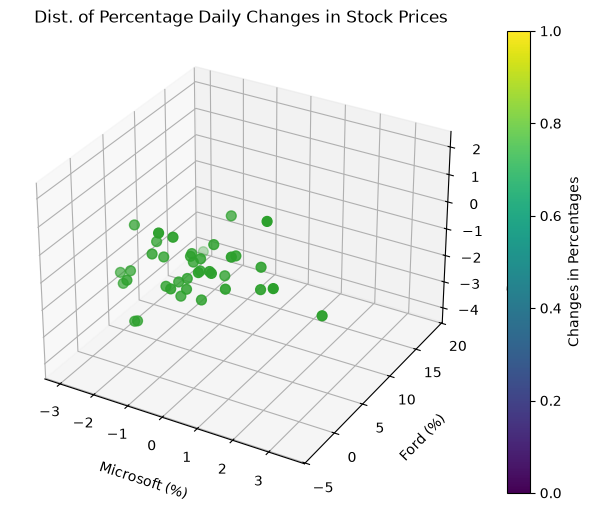

In [74]:
%matplotlib inline

beta = delta_clean.dropna()

fig = plt.figure(figsize = (9,6))
ax = fig.add_subplot(projection = '3d')
p = ax.scatter(delta_clean.msft_adj,delta_clean.f_adj,delta_clean.bac_adj,
          c = 'tab:green', s = 50)
ax.set_xlabel('Microsoft (%)', labelpad = 10)
ax.set_ylabel('Ford (%)', labelpad = 10)
ax.set_zlabel('Bank of America (%)', labelpad = 10)
plt.title('Dist. of Percentage Daily Changes in Stock Prices')
plt.colorbar(p, label = 'Changes in Percentages')
plt.show()

In [75]:
meanValue = delta_clean.mean()
covValue = delta_clean.cov()
print('Mean Value: ', ' \n', meanValue)
print('Covariant Value: ', ' \n', covValue)

Mean Value:   
 Ticker
bac_adj    -0.254781
f_adj       0.312448
msft_adj   -0.045437
dtype: float64
Covariant Value:   
 Ticker     bac_adj      f_adj  msft_adj
Ticker                                 
bac_adj   1.161539  -1.727546  0.772991
f_adj    -1.727546  12.397403 -1.420206
msft_adj  0.772991  -1.420206  1.829450


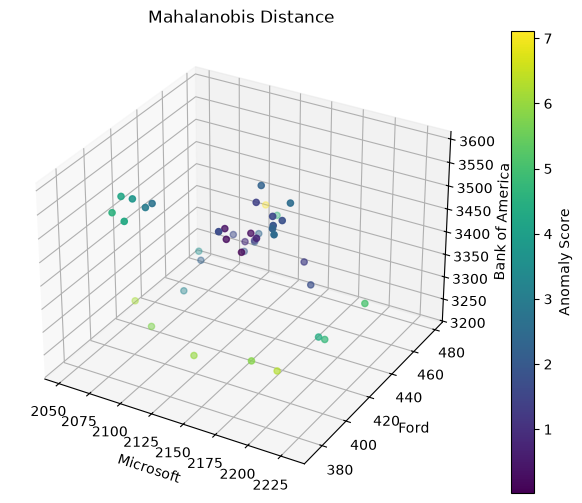

In [76]:
delta_clean = delta.dropna()

X = delta_clean[['msft_adj', 'f_adj', 'bac_adj']].to_numpy()

S = np.cov(X, rowvar = False)
S_inv = np.linalg.inv(S)

X_centered = X - X.mean(axis = 0)

def mahalanobis(row):
    return np.dot(np.dot(row, S_inv), row)

anomaly_score = np.apply_along_axis(mahalanobis, axis = 1, arr = X_centered)

fig = plt.figure(figsize = (10, 6))
ax = fig.add_subplot(111, projection = '3d')
p = ax.scatter(delta_clean.msft_adj, 
               delta_clean.f_adj, 
               delta_clean.bac_adj, 
               c = anomaly_score, 
               cmap = 'viridis')
ax.set_xlabel('Microsoft')
ax.set_ylabel('Ford')
ax.set_zlabel('Bank of America')
plt.title('Mahalanobis Distance')
plt.colorbar(p, label = 'Anomaly Score')
plt.show()


In [77]:
anom = pd.DataFrame(anomaly_score, index = delta_clean.index, columns = ['Anomaly score'])
result = pd.concat((delta,anom), axis = 1)
result.nlargest(3,'Anomaly score')

,bac_adj,f_adj,msft_adj,Anomaly score
Date,,,,
2007-07-02,3371.861649,479.213572,2104.500198,7.112353
2007-07-24,3223.506165,410.612440,2179.508591,6.303475
2007-07-31,3241.963959,423.040056,2051.426697,6.162939


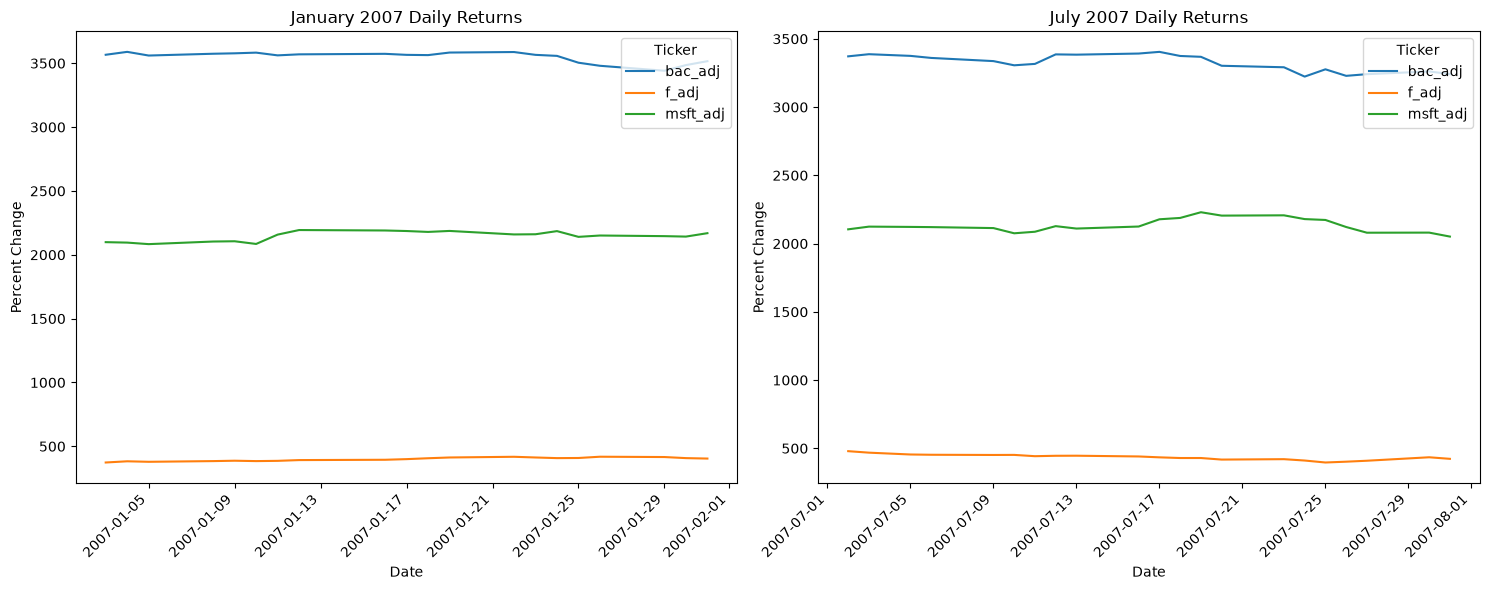

In [87]:
fig, (ax1, ax2) = plt.subplots(nrows = 1, ncols = 2, figsize = (15, 6))

jan_ts = delta_clean.loc['2007-01']
jul_ts = delta_clean.loc['2007-07']

jan_ts.plot.line(ax = ax1)
ax1.set_title('January 2007 Daily Returns')
ax1.set_ylabel('Percent Change')
ax1.tick_params(axis = 'x', rotation = 45)

jul_ts.plot.line(ax = ax2)
ax2.set_title('July 2007 Daily Returns')
ax2.set_ylabel('Percent Change')
ax2.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()

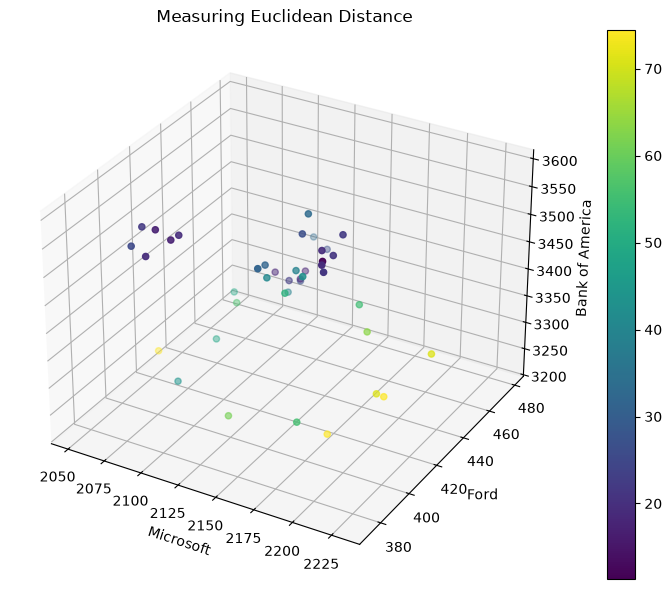

In [91]:
knn = 4
nbrs = NearestNeighbors(n_neighbors = knn, metric = distance.euclidean).fit(delta_clean.to_numpy())
distances, incicies = nbrs.kneighbors(delta_clean.to_numpy())

anomaly_score = distances[:, knn - 1]

fig = plt.figure(figsize = (10, 6))
ax = fig.add_subplot(111, projection = '3d')
p = ax.scatter(
    delta_clean.msft_adj,
    delta_clean.f_adj,
    delta_clean.bac_adj,
    c = anomaly_score,
    cmap = 'viridis'
)
ax.set_xlabel('Microsoft')
ax.set_ylabel('Ford')
ax.set_zlabel('Bank of America')
plt.title('Measuring Euclidean Distance')
fig.colorbar(p)
plt.tight_layout()
plt.show()

In [94]:
anom = pd.DataFrame(anomaly_score, index=delta_clean.index, columns=['Anomaly score'])
result = pd.concat((delta,anom), axis = 1)
result.nlargest(5,'Anomaly score')

,bac_adj,f_adj,msft_adj,Anomaly score
Date,,,,
2007-07-23,3291.873932,420.554543,2207.106400,74.395135
2007-07-24,3223.506165,410.612440,2179.508591,74.395135
2007-07-31,3241.963959,423.040056,2051.426697,74.246063
2007-07-19,3368.445206,429.005241,2229.750443,71.076880
2007-07-20,3302.811432,417.571926,2204.983330,71.076880


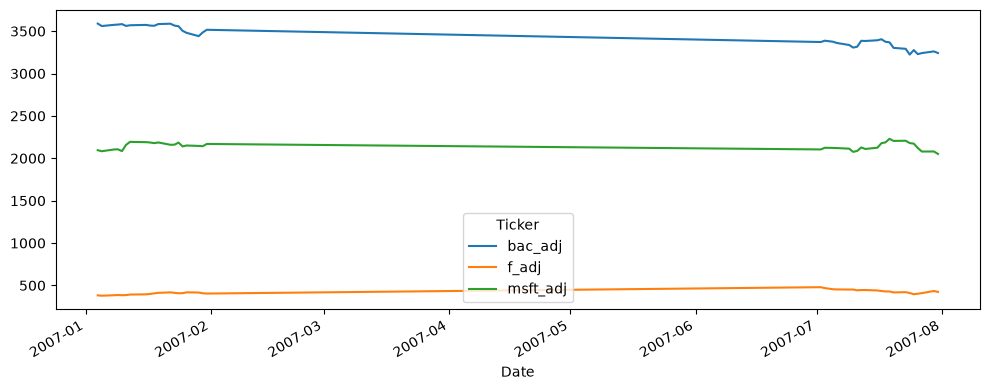

In [96]:
fig= plt.figure(figsize = (10, 4))

ax = fig.add_subplot(111)
ts.plot.line(ax = ax)
ax1.set_title('2007 Daily Returns')
ax1.set_ylabel('Percent Change')
ax1.tick_params(axis = 'x', rotation = 45)

plt.tight_layout()
plt.show()